# Ejercicio 14. El ciclo completo sobre el problema de la celebridad

Este cuaderno acompaña al informe [`ejercicio-14.md`](ejercicio-14.md). Ejecuta el
algoritmo, comprueba su costo, implementa el adversario de la cota mínima y lo prueba
contra varias estrategias, busca por fuerza bruta el número exacto de preguntas para
$n\le4$ y genera `ejercicio-14.png`. Las secciones siguen la numeración del informe.

Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.

In [1]:
import math
from itertools import product
from random import Random

import matplotlib.pyplot as plt
from IPython.display import Image, display

## 1. El problema y el modelo

Una instancia es una matriz `K` donde `K[a][b]` dice si `a` conoce a `b` (la
diagonal no se usa). Una **celebridad** es una persona `c` a la que todos conocen y
que no conoce a nadie. Un algoritmo solo accede a `K` con la pregunta `knows(a, b)`,
con `a != b`, y su costo es el número de preguntas. Se supone la **promesa** de que
existe una celebridad.

In [2]:
def celebrity_of(K):
    """La celebridad de la matriz K, o None. Mira todos los pares: es el oráculo."""
    n = len(K)
    found = [c for c in range(n)
             if all(K[x][c] for x in range(n) if x != c)
             and not any(K[c][y] for y in range(n) if y != c)]
    assert len(found) <= 1, "a lo sumo una celebridad"
    return found[0] if found else None


def planted(n, c, rng):
    """Matriz con celebridad c; el resto de las relaciones, al azar."""
    K = [[rng.random() < 0.5 for _ in range(n)] for _ in range(n)]
    for x in range(n):
        K[x][x] = False
        if x != c:
            K[x][c] = True
            K[c][x] = False
    return K


def oracle(K):
    """Devuelve knows(a, b) y un contador de preguntas."""
    count = [0]

    def knows(a, b):
        if a == b:
            raise ValueError("no se pregunta por una persona consigo misma")
        count[0] += 1
        return K[a][b]
    return knows, count


rng = Random(14)
for n in range(1, 8):
    for c in range(n):
        assert celebrity_of(planted(n, c, rng)) == c
K = [[False, True], [True, False]]
assert celebrity_of(K) is None          # dos personas que se conocen: ninguna celebridad
print("ok: unicidad y generador de instancias con celebridad")

ok: unicidad y generador de instancias con celebridad


## 2. El algoritmo, 3. su correctitud y 4. su costo

Un candidato `c` y una pasada. Si `c` conoce a `x`, `c` no es la celebridad y el
candidato pasa a ser `x`; si no, `x` no es la celebridad.

In [3]:
def find_celebrity(n, knows):
    """Con la promesa de que existe una celebridad, devuelve (c, preguntas)."""
    if n < 1:
        raise ValueError("se requiere al menos una persona")
    candidate, asked = 0, 0
    for other in range(1, n):
        asked += 1
        if knows(candidate, other):
            candidate = other
    return candidate, asked

In [4]:
rng = Random(141)
instances = 0
for n in list(range(1, 13)) + [50, 200, 1000]:
    for _ in range(20 if n < 100 else 3):
        c = rng.randrange(n)
        K = planted(n, c, rng)
        knows, count = oracle(K)
        answer, asked = find_celebrity(n, knows)
        assert answer == c and asked == count[0] == n - 1
        instances += 1
print(f"ok: {instances} instancias; siempre n - 1 preguntas y la respuesta correcta")

# el invariante: tras procesar 0..i, todos los de 0..i distintos del candidato
# ya no pueden ser la celebridad (se comprueba contra la celebridad real)
rng = Random(142)
checked = 0
for _ in range(300):
    n = rng.randint(2, 12)
    c = rng.randrange(n)
    K = planted(n, c, rng)
    candidate = 0
    for other in range(1, n):
        candidate = other if K[candidate][other] else candidate
        eliminated = set(range(other + 1)) - {candidate}
        assert c not in eliminated          # la celebridad nunca se elimina
        checked += 1
print(f"ok: la celebridad nunca queda eliminada, {checked} pasos comprobados")

ok: 266 instancias; siempre n - 1 preguntas y la respuesta correcta


ok: la celebridad nunca queda eliminada, 1810 pasos comprobados


## 5. Cota mínima

**Información.** Hay $n$ respuestas posibles, así que alcanza con $\lceil\log_2n\rceil$
preguntas de tipo sí o no, mucho menos que $n-1$.

**Adversario.** `Adversary` mantiene el conjunto `alive` de personas que todavía
pueden ser la celebridad y contesta como en el informe, recordando sus respuestas.
`instance_for` construye, para cada `c` en `alive`, una matriz con celebridad `c`
consistente con **todas** las respuestas dadas.

In [5]:
class Adversary:
    def __init__(self, n):
        self.n, self.alive, self.log, self.memo = n, set(range(n)), [], {}

    def knows(self, a, b):
        if a == b:
            raise ValueError("no se pregunta por una persona consigo misma")
        if (a, b) in self.memo:             # una pregunta repetida se contesta igual
            return self.memo[(a, b)]
        if a in self.alive and b in self.alive:
            answer = True                   # a conoce a alguien: deja de ser candidata
            self.alive.discard(a)
        elif a in self.alive:               # b ya no es candidata: a no la conoce
            answer = False
        else:                               # a ya no es candidata
            answer = True
        self.memo[(a, b)] = answer
        self.log.append((a, b, answer))
        return answer


def instance_for(n, c, log):
    K = [[False] * n for _ in range(n)]
    for x in range(n):
        if x != c:
            K[x][c] = True
    for a, b, answer in log:
        if a != c and b != c:
            K[a][b] = answer
    assert all(K[a][b] == answer for a, b, answer in log), "inconsistente con el registro"
    return K


class Stop(Exception):
    pass


def limited(adversary, limit):
    def knows(a, b):
        if len(adversary.log) >= limit and (a, b) not in adversary.memo:
            raise Stop
        return adversary.knows(a, b)
    return knows


def strategy_elimination(n, knows, rng):
    find_celebrity(n, knows)


def strategy_random(n, knows, rng):
    while True:
        a, b = rng.sample(range(n), 2)
        knows(a, b)


def strategy_scan(n, knows, rng):
    for a in range(n):
        for b in range(n):
            if a != b:
                knows(a, b)


STRATEGIES = [("eliminación", strategy_elimination),
              ("pares al azar", strategy_random),
              ("barrido por filas", strategy_scan)]

Para cada estrategia y cada límite $q<n-1$ se corta la ejecución tras $q$ preguntas
nuevas. Se comprueba que quedan al menos $n-q\ge2$ candidatas, y para dos de ellas se
construyen las dos matrices con celebridades distintas, consistentes con el mismo
registro: ningún algoritmo puede distinguirlas.

In [6]:
n = 10
pairs_checked = 0
for name, strategy in STRATEGIES:
    for q in range(0, n - 1):
        adversary = Adversary(n)
        try:
            strategy(n, limited(adversary, q), Random(q))
        except Stop:
            pass
        asked = len(adversary.log)
        assert asked <= q and len(adversary.alive) >= n - asked >= 2
        c1, c2 = sorted(adversary.alive)[:2]
        K1, K2 = instance_for(n, c1, adversary.log), instance_for(n, c2, adversary.log)
        assert celebrity_of(K1) == c1 and celebrity_of(K2) == c2 and c1 != c2
        # las dos matrices dan las mismas respuestas a todo lo preguntado
        assert all(K1[a][b] == K2[a][b] == ans for a, b, ans in adversary.log)
        pairs_checked += 1
print(f"ok: {pairs_checked} cortes; en todos quedan dos celebridades posibles distintas")

# la estrategia de eliminación, sin cortar: n - 1 preguntas y una sola candidata
adversary = Adversary(n)
answer, asked = find_celebrity(n, adversary.knows)
assert asked == len(adversary.log) == n - 1 and adversary.alive == {answer}
print("ok: contra el adversario, la eliminación hace exactamente n - 1 preguntas")

ok: 27 cortes; en todos quedan dos celebridades posibles distintas
ok: contra el adversario, la eliminación hace exactamente n - 1 preguntas


## 5.4. Verificación independiente por fuerza bruta

Para $n\le4$ se enumeran **todas** las instancias con celebridad y se busca, con un
juego mínimo-máximo, el menor número $q$ tal que alguna estrategia adaptativa
identifica la celebridad en todas ellas con a lo sumo $q$ preguntas. No usa el
adversario ni el algoritmo.

In [7]:
def exhaustive_min_questions(n):
    pairs = [(a, b) for a in range(n) for b in range(n) if a != b]
    insts = []
    for c in range(n):
        free = [i for i, (a, b) in enumerate(pairs) if a != c and b != c]
        for bits in product([False, True], repeat=len(free)):
            row = [False] * len(pairs)
            for i, (a, b) in enumerate(pairs):
                row[i] = (b == c)
            for i, bit in zip(free, bits):
                row[i] = bit
            insts.append((c, tuple(row)))

    def can(group, q):
        if len({c for c, _ in group}) <= 1:
            return True
        if q == 0:
            return False
        for i in range(len(pairs)):
            yes = [x for x in group if x[1][i]]
            no = [x for x in group if not x[1][i]]
            if yes and no and can(yes, q - 1) and can(no, q - 1):
                return True
        return False

    q = 0
    while not can(insts, q):
        q += 1
    return len(insts), q


print(f"{'n':>2} {'instancias':>11} {'mínimo exacto':>14} {'n - 1':>6} {'⌈log2 n⌉':>9}")
for n in [2, 3, 4]:
    count, q = exhaustive_min_questions(n)
    assert q == n - 1
    print(f"{n:>2} {count:>11} {q:>14} {n - 1:>6} {math.ceil(math.log2(n)):>9}")

 n  instancias  mínimo exacto  n - 1  ⌈log2 n⌉
 2           2              1      1         1
 3          12              2      2         2
 4         256              3      3         2


## 6. La promesa y el modelo

Sin la promesa, el algoritmo anterior devuelve a alguien aunque no haya celebridad.
Se añade una verificación, que cuesta a lo sumo $2(n-1)$ preguntas más. Se mide en
instancias con celebridad y en instancias a las que se les quitó una sola relación
`K[x][c]`, que no tienen ninguna.

In [8]:
def find_celebrity_or_none(n, knows):
    c, asked = find_celebrity(n, knows)
    for other in range(n):
        if other != c:
            asked += 2
            if knows(c, other) or not knows(other, c):
                return None, asked
    return c, asked


rng = Random(143)
stats = dict(with_ok=0, with_cost=set(), without_naive_wrong=0, without_ok=0, total=0)
for _ in range(1000):
    n = rng.randint(2, 12)
    c = rng.randrange(n)
    K = planted(n, c, rng)
    knows, _ = oracle(K)
    answer, asked = find_celebrity_or_none(n, knows)
    assert answer == c and asked == 3 * (n - 1)
    stats["with_ok"] += 1

    x = rng.choice([p for p in range(n) if p != c])
    K[x][c] = False                              # ahora nadie es celebridad
    assert celebrity_of(K) is None
    knows, _ = oracle(K)
    naive, _ = find_celebrity(n, knows)
    stats["without_naive_wrong"] += celebrity_of(K) != naive   # siempre: no hay celebridad
    knows, _ = oracle(K)
    answer, asked = find_celebrity_or_none(n, knows)
    assert answer is None and asked <= 3 * (n - 1)
    stats["without_ok"] += 1
    stats["total"] += 1
print(f"con celebridad: {stats['with_ok']} de {stats['total']} correctas, siempre 3(n-1) preguntas")
print(f"sin celebridad: el algoritmo sin verificar devuelve a alguien en {stats['without_naive_wrong']} "
      f"de {stats['total']}; con verificación responde None en {stats['without_ok']}")

con celebridad: 1000 de 1000 correctas, siempre 3(n-1) preguntas
sin celebridad: el algoritmo sin verificar devuelve a alguien en 1000 de 1000; con verificación responde None en 1000


## 7. Costo medido y figura

A la izquierda, las preguntas del algoritmo, la cota del adversario (la misma recta),
la cota de información y el algoritmo con verificación. A la derecha, el número de
candidatas que deja el adversario tras $q$ preguntas, para $n=16$, con las tres
estrategias y la cota $n-q$.

    n  preguntas  cota adversario  ⌈log2 n⌉  con verificación
    2          1                1         1                 3
    4          3                3         2                 9
   16         15               15         4                45
   64         63               63         6               189
  256        255              255         8               765
 1024       1023             1023        10              3069


       eliminación: 16 15 14 13 12 11 10  9  8  7  6  5  4  3  2  1
     pares al azar: 16 15 15 14 13 13 12 12 12 12 11 11 11 10  9  8
 barrido por filas: 16 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15


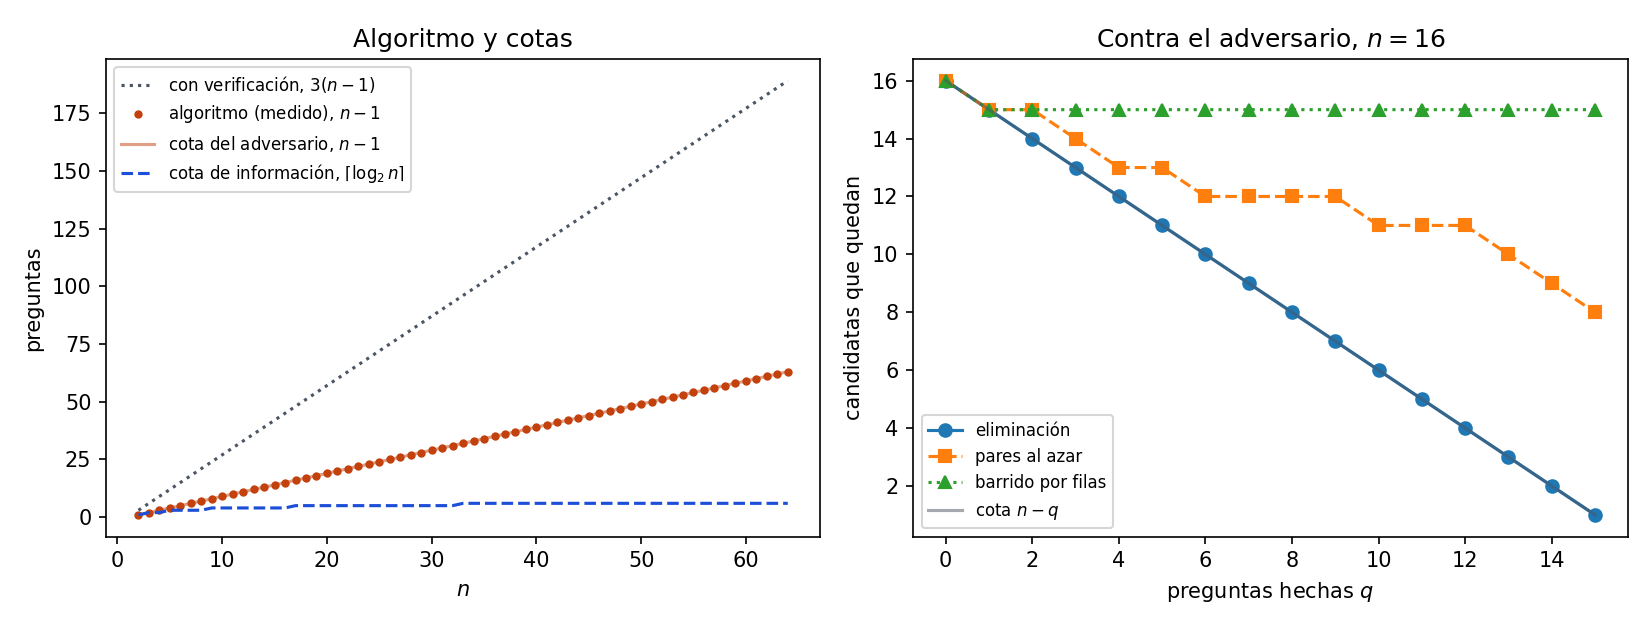

In [9]:
sizes = list(range(2, 65))
measured = []
rng = Random(144)
for n in sizes:
    c = rng.randrange(n)
    knows, count = oracle(planted(n, c, rng))
    find_celebrity(n, knows)
    measured.append(count[0])
assert measured == [n - 1 for n in sizes]

print(f"{'n':>5} {'preguntas':>10} {'cota adversario':>16} {'⌈log2 n⌉':>9} {'con verificación':>17}")
for n in [2, 4, 16, 64, 256, 1024]:
    print(f"{n:>5} {n - 1:>10} {n - 1:>16} {math.ceil(math.log2(n)):>9} {3 * (n - 1):>17}")

N = 16
curves = {}
for name, strategy in STRATEGIES:
    curve = []
    for q in range(0, N):
        adversary = Adversary(N)
        try:
            strategy(N, limited(adversary, q), Random(7))
        except Stop:
            pass
        curve.append(len(adversary.alive))
        assert curve[-1] >= N - q
    curves[name] = curve

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
left.plot(sizes, [3 * (n - 1) for n in sizes], ":", color="#4b5563", label="con verificación, $3(n-1)$")
left.plot(sizes, measured, "o", color="#c2410c", markersize=3, label="algoritmo (medido), $n-1$")
left.plot(sizes, [n - 1 for n in sizes], "-", color="#c2410c", alpha=0.5, label="cota del adversario, $n-1$")
left.plot(sizes, [math.ceil(math.log2(n)) for n in sizes], "--", color="#1d4ed8",
          label="cota de información, $\\lceil\\log_2 n\\rceil$")
left.set_xlabel("$n$")
left.set_ylabel("preguntas")
left.set_title("Algoritmo y cotas")
left.legend(fontsize=8)

styles = {"eliminación": "o-", "pares al azar": "s--", "barrido por filas": "^:"}
for name, curve in curves.items():
    right.plot(range(len(curve)), curve, styles[name], label=name)
right.plot(range(N), [N - q for q in range(N)], "-", color="#4b5563", alpha=0.5, label="cota $n-q$")
right.set_xlabel("preguntas hechas $q$")
right.set_ylabel("candidatas que quedan")
right.set_title("Contra el adversario, $n=16$")
right.legend(fontsize=8)
fig.tight_layout()
fig.savefig("ejercicio-14.png", dpi=150)
plt.close(fig)
for name, curve in curves.items():
    print(f"{name:>18}: " + " ".join(f"{v:>2}" for v in curve))
display(Image("ejercicio-14.png"))